In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

In [162]:
# File path
file_path = r"D:\MG\！CUHKSZ\Berkeley 交流\❗课\STAT 153 - Intro to Time Series\Homework\2_CAPOP.xlsx"

# Read the data
df = pd.read_excel(file_path, sheet_name='Annual', header=0)
df.columns = ['year', 'population']
df['year'] = pd.to_datetime(df['year']).dt.year  # Extract year
df = df[df['year'] < 2024]  # Exclude 2024
df['t'] = df['year'] - 1900  # Create time variable t (years since 1900)

# a) Linear Model Fit

In [163]:
# Prepare data for linear model
X = np.column_stack([np.ones(len(df)), df['t']])
y = df['population']

In [164]:
# Bayesian linear regression with non-informative prior
n = len(y)
p = 2
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
s2 = np.sum((y - X @ beta_hat)**2) / (n - p)
cov_beta = s2 * np.linalg.inv(X.T @ X)
se_beta = np.sqrt(np.diag(cov_beta))

In [165]:
# Posterior means and 95% credible intervals
beta0_est = beta_hat[0]
beta1_est = beta_hat[1]
beta0_ci = beta0_est + stats.t.ppf([0.025, 0.975], n-p) * se_beta[0]
beta1_ci = beta1_est + stats.t.ppf([0.025, 0.975], n-p) * se_beta[1]

In [166]:
print(f"β0 estimate: {beta0_est:.2f}, 95% CI: [{beta0_ci[0]:.2f}, {beta0_ci[1]:.2f}]")
print(f"β1 estimate: {beta1_est:.2f}, 95% CI: [{beta1_ci[0]:.2f}, {beta1_ci[1]:.2f}]")

β0 estimate: -3968.40, 95% CI: [-4730.96, -3205.84]
β1 estimate: 359.14, 95% CI: [348.43, 369.86]


# b) Posterior Samples Plot

In [167]:
# Sample from posterior for σ²
sigma2_samples = (n - p) * s2 / stats.chi2.rvs(n - p, size=100)

# Precompute (X^T X)^{-1}
inv_XTX = np.linalg.inv(X.T @ X)

# Sample from posterior for β given σ²
beta_samples = np.array([stats.multivariate_normal.rvs(beta_hat, sigma2_i * inv_XTX) for sigma2_i in sigma2_samples])

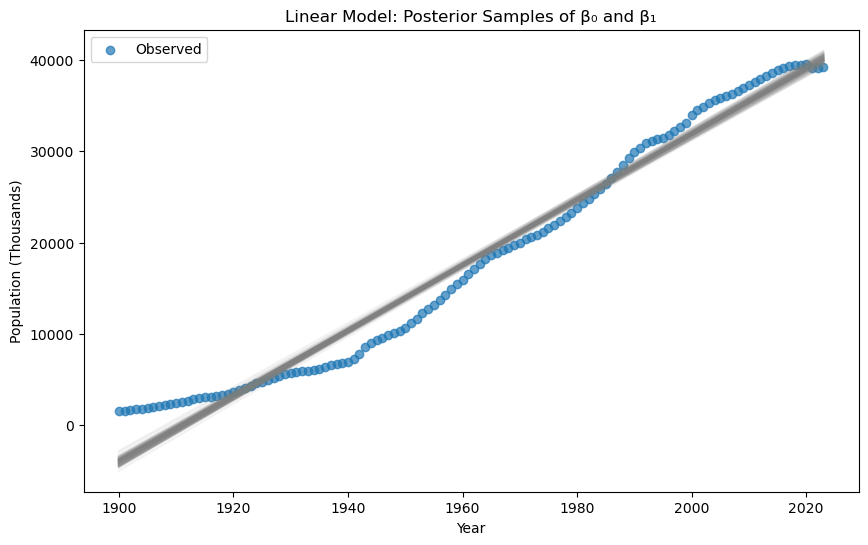

In [168]:
# Plot observed data and posterior samples
plt.figure(figsize=(10, 6))
plt.scatter(df['year'], y, alpha=0.7, label='Observed')
for i in range(100):
    y_pred = beta_samples[i, 0] + beta_samples[i, 1] * df['t']
    plt.plot(df['year'], y_pred, alpha=0.1, color='gray')
plt.xlabel('Year')
plt.ylabel('Population (Thousands)')
plt.title('Linear Model: Posterior Samples of β₀ and β₁')
plt.legend()
plt.show()

# c) 2024 Prediction Using Linear Model

In [169]:
t_2024 = 124  # t = 2024 - 1900
y_pred_2024 = beta_hat[0] + beta_hat[1] * t_2024
se_pred = np.sqrt(s2 * (1 + np.array([1, t_2024]) @ np.linalg.inv(X.T @ X) @ np.array([1, t_2024])))
ci_2024 = y_pred_2024 + stats.t.ppf([0.025, 0.975], n-p) * se_pred

In [170]:
print(f"2024 prediction: {y_pred_2024:.2f}, 95% CI: [{ci_2024[0]:.2f}, {ci_2024[1]:.2f}]")

2024 prediction: 40565.19, 95% CI: [36224.56, 44905.83]


# d) Log-Linear Model Fit

In [171]:
log_y = np.log(y)
X = np.column_stack([np.ones(len(df)), df['t']])
beta_hat_log = np.linalg.inv(X.T @ X) @ X.T @ log_y
s2_log = np.sum((log_y - X @ beta_hat_log)**2) / (n - p)
cov_beta_log = s2_log * np.linalg.inv(X.T @ X)
se_beta_log = np.sqrt(np.diag(cov_beta_log))

In [172]:
beta0_log_est = beta_hat_log[0]
beta1_log_est = beta_hat_log[1]
beta0_log_ci = beta0_log_est + stats.t.ppf([0.025, 0.975], n-p) * se_beta_log[0]
beta1_log_ci = beta1_log_est + stats.t.ppf([0.025, 0.975], n-p) * se_beta_log[1]

In [173]:
print(f"β0 estimate: {beta0_log_est:.4f}, 95% CI: [{beta0_log_ci[0]:.4f}, {beta0_log_ci[1]:.4f}]")
print(f"β1 estimate: {beta1_log_est:.4f}, 95% CI: [{beta1_log_ci[0]:.4f}, {beta1_log_ci[1]:.4f}]")

β0 estimate: 7.7488, 95% CI: [7.6709, 7.8266]
β1 estimate: 0.0271, 95% CI: [0.0260, 0.0282]


# e) Posterior Probability That $\beta_1 > 0.03$

In [174]:
# Posterior distribution of β1 is t-distributed
t_dist = stats.t(df=n-p, loc=beta1_log_est, scale=se_beta_log[1])
prob = 1 - t_dist.cdf(0.03)

In [175]:
print(f"P(β1 > 0.03 | data) = {prob:.4f}")

P(β1 > 0.03 | data) = 0.0000


# f) 2024 Prediction Using Log-Linear Model

In [176]:
log_y_pred_2024 = beta_hat_log[0] + beta_hat_log[1] * t_2024
x0 = np.array([1, t_2024])
se_log_pred = np.sqrt(s2_log * (1 + x0 @ np.linalg.inv(X.T @ X) @ x0))
ci_log_pred = log_y_pred_2024 + stats.t.ppf([0.025, 0.975], n-p) * se_log_pred

In [177]:
# Transform back to original scale
y_pred_2024_log = np.exp(log_y_pred_2024)
ci_2024_log = np.exp(ci_log_pred)

In [178]:
print(f"2024 prediction: {y_pred_2024_log:.2f}, 95% PI: [{ci_2024_log[0]:.2f}, {ci_2024_log[1]:.2f}]")

2024 prediction: 66909.89, 95% PI: [42960.95, 104209.36]


# g) Quadratic Log-Linear Model Fit

In [179]:
X_quad = np.column_stack([np.ones(len(df)), df['t'], df['t']**2])
beta_hat_quad = np.linalg.inv(X_quad.T @ X_quad) @ X_quad.T @ log_y
s2_quad = np.sum((log_y - X_quad @ beta_hat_quad)**2) / (n - 3)
log_y_pred_2024_quad = beta_hat_quad[0] + beta_hat_quad[1] * t_2024 + beta_hat_quad[2] * t_2024**2
se_quad_pred = np.sqrt(s2_quad * (1 + np.array([1, t_2024, t_2024**2]) @ np.linalg.inv(X_quad.T @ X_quad) @ np.array([1, t_2024, t_2024**2])))
ci_quad_pred = log_y_pred_2024_quad + stats.t.ppf([0.025, 0.975], n-3) * se_quad_pred
y_pred_2024_quad = np.exp(log_y_pred_2024_quad)
ci_2024_quad = np.exp(ci_quad_pred)

In [180]:
print(f"2024 prediction: {y_pred_2024_quad:.2f}, 95% CI: [{ci_2024_quad[0]:.2f}, {ci_2024_quad[1]:.2f}]")

2024 prediction: 40933.48, 95% CI: [37561.41, 44608.27]
